# Examining Sub-Research Research Question 3: Language

The third sub-research question is as follows: **'Are there differences in content between homosexual and heterosexual fan fiction on Archive of Our Own, regarding variables such as the language, date published, or word count?**

In [1]:
# Import package
import polars as pl
import pyarrow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [3]:
# Change all language names to English
language_names = {
    "Español": "Spanish",
    "中文-普通话 國語": "Mandarin",
    "Русский": "Russian",
    "Français": "French",
    "Português brasileiro": "Brazilian Portuguese",
    "Bahasa Indonesia": "Indonesian",
    "Українська": "Ukrainian",
    "Italiano": "Italian",
    "Polski": "Polish",
    "Tiếng Việt": "Vietnamese",
    "беларуская": "Belarusian",
    "العربية": "Arabic",
    "日本語": "Japanese",
    "Čeština": "Czech",
    "Türkçe": "Turkish",
    "Deutsch": "German",
    "Català": "Catalan"
}

df_metadata = df_metadata.with_columns(
    pl.col("Language").replace(language_names)
)

In [4]:
# Calculate the language frequencies
ff_mm_language_amt = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("Language").value_counts()).unnest("Language").sort("count", descending=True)
fm_language_amt = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("Language").value_counts()).unnest("Language").sort("count", descending=True)

print("Homosexual Fan Works Amount:")
ff_mm_language_amt.show(17)
print("Heterosexual Fan Works Amount:")
fm_language_amt.show(13)

# Turn the languages into lists
ff_mm_language_list = ff_mm_language_amt.to_series(0).to_list()
fm_language_list = fm_language_amt.to_series(0).to_list()

print("Homosexual Languages: ", ff_mm_language_list)
print("Heterosexual Languages: ", fm_language_list)

Homosexual Fan Works Amount:


Language,count
str,u32
"""English""",5252
"""Mandarin""",207
"""Spanish""",127
"""Russian""",38
"""French""",30
"""Brazilian Portuguese""",14
"""Vietnamese""",12
"""Ukrainian""",10
"""Italian""",7


Heterosexual Fan Works Amount:


Language,count
str,u32
"""English""",4142
"""Spanish""",42
"""Mandarin""",26
"""Russian""",26
"""French""",7
"""Brazilian Portuguese""",3
"""Italian""",2
"""Indonesian""",2
"""Ukrainian""",2


Homosexual Languages:  ['English', 'Mandarin', 'Spanish', 'Russian', 'French', 'Brazilian Portuguese', 'Vietnamese', 'Ukrainian', 'Italian', 'Japanese', 'Czech', 'Turkish', 'Arabic', 'Indonesian', 'German', 'Polish', 'Catalan']
Heterosexual Languages:  ['English', 'Spanish', 'Mandarin', 'Russian', 'French', 'Brazilian Portuguese', 'Italian', 'Indonesian', 'Ukrainian', 'Belarusian', 'Arabic', 'Vietnamese', 'Polish']


## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [6]:
# Filtered by F/F + M/M based on language
df_ff_mm_languages_ratings = pl.DataFrame()
for ff_mm_language in ff_mm_language_list:
    ff_mm_language_ratings = df_metadata.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Language") == ff_mm_language)
    ).select(pl.col("Rating").value_counts()).unnest("Rating").sort("Rating").unpivot(index="Rating", variable_name="count").pivot("Rating", index="count").drop("count").with_columns(pl.lit(ff_mm_language).alias("Language")) # Filter based on language
    df_ff_mm_languages_ratings = pl.concat([df_ff_mm_languages_ratings, ff_mm_language_ratings], how="diagonal") # Concatenate the DataFrames

df_ff_mm_languages_ratings = df_ff_mm_languages_ratings.select(['Language', 'Not Rated', 'General Audiences', 'Teen And Up Audiences', 'Mature', 'Explicit']) # Reorder the columns
df_ff_mm_languages_ratings = df_ff_mm_languages_ratings.with_columns(pl.all().fill_null(strategy="zero"))

# Filtered by F/M based on language
df_fm_languages_ratings = pl.DataFrame()
for fm_language in fm_language_list:
    fm_language_ratings = df_metadata.filter(
        (pl.col("Category") == "F/M") &
        (pl.col("Language") == fm_language)
    ).select(pl.col("Rating").value_counts()).unnest("Rating").sort("Rating").unpivot(index="Rating", variable_name="count").pivot("Rating", index="count").drop("count").with_columns(pl.lit(fm_language).alias("Language")) # Filter based on language
    df_fm_languages_ratings = pl.concat([df_fm_languages_ratings, fm_language_ratings], how="diagonal") # Concatenate the DataFrames

df_fm_languages_ratings = df_fm_languages_ratings.select(['Language', 'Not Rated', 'General Audiences', 'Teen And Up Audiences', 'Mature', 'Explicit']) # Reorder the columns
df_fm_languages_ratings = df_fm_languages_ratings.with_columns(pl.all().fill_null(strategy="zero"))

print("Homosexual Language Ratings Amount:")
df_ff_mm_languages_ratings.show(17)
print("Heterosexual Language Ratings Amount:")
df_fm_languages_ratings.show(13)

# Calculate the Ratings percentage distribution per language
df_ff_mm_languages_percentages_ratings = df_ff_mm_languages_ratings.with_columns(
    (pl.col("Not Rated") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Not Rated"), (pl.col("General Audiences") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("General Audiences"), (pl.col("Teen And Up Audiences") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Teen And Up Audiences"), (pl.col("Mature") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Mature"), (pl.col("Explicit") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Explicit")
).with_columns(pl.exclude("Language")) # Filtered by F/F + M/M
df_fm_languages_percentages_ratings = df_fm_languages_ratings.with_columns(
     (pl.col("Not Rated") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Not Rated"), (pl.col("General Audiences") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("General Audiences"), (pl.col("Teen And Up Audiences") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Teen And Up Audiences"), (pl.col("Mature") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Mature"), (pl.col("Explicit") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Explicit")).with_columns(pl.exclude("Language")
) # Filtered by F/M

print("Homosexual Language Ratings Percentage Distribution:")
df_ff_mm_languages_percentages_ratings.show(17)
print("Heterosexual Language Ratings Percentage Distribution:")
df_fm_languages_percentages_ratings.show(13)

Homosexual Language Ratings Amount:


Language,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
str,u32,u32,u32,u32,u32
"""English""",482,1271,1707,732,1060
"""Mandarin""",45,32,22,58,50
"""Spanish""",14,17,21,29,46
"""Russian""",1,9,13,5,10
"""French""",1,15,7,4,3
"""Brazilian Portuguese""",4,5,2,3,0
"""Vietnamese""",2,3,1,2,4
"""Ukrainian""",1,2,4,3,0
"""Italian""",0,4,3,0,0


Heterosexual Language Ratings Amount:


Language,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
str,u32,u32,u32,u32,u32
"""English""",381,1170,1191,605,795
"""Spanish""",1,15,9,6,11
"""Mandarin""",7,3,5,5,6
"""Russian""",1,8,8,5,4
"""French""",0,5,1,0,1
"""Brazilian Portuguese""",0,2,0,0,1
"""Italian""",0,0,2,0,0
"""Indonesian""",0,1,1,0,0
"""Ukrainian""",0,0,2,0,0


Homosexual Language Ratings Percentage Distribution:


Language,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
str,f64,f64,f64,f64,f64
"""English""",9.177456,24.200305,32.501904,13.937548,20.182788
"""Mandarin""",21.73913,15.458937,10.628019,28.019324,24.154589
"""Spanish""",11.023622,13.385827,16.535433,22.834646,36.220472
"""Russian""",2.631579,23.684211,34.210526,13.157895,26.315789
"""French""",3.333333,50.0,23.333333,13.333333,10.0
"""Brazilian Portuguese""",28.571429,35.714286,14.285714,21.428571,0.0
"""Vietnamese""",16.666667,25.0,8.333333,16.666667,33.333333
"""Ukrainian""",10.0,20.0,40.0,30.0,0.0
"""Italian""",0.0,57.142857,42.857143,0.0,0.0


Heterosexual Language Ratings Percentage Distribution:


Language,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
str,f64,f64,f64,f64,f64
"""English""",9.198455,28.247224,28.754225,14.60647,19.193626
"""Spanish""",2.380952,35.714286,21.428571,14.285714,26.190476
"""Mandarin""",26.923077,11.538462,19.230769,19.230769,23.076923
"""Russian""",3.846154,30.769231,30.769231,19.230769,15.384615
"""French""",0.0,71.428571,14.285714,0.0,14.285714
"""Brazilian Portuguese""",0.0,66.666667,0.0,0.0,33.333333
"""Italian""",0.0,0.0,100.0,0.0,0.0
"""Indonesian""",0.0,50.0,50.0,0.0,0.0
"""Ukrainian""",0.0,0.0,100.0,0.0,0.0


### 1.2 Visualizing the Ratings Datasets

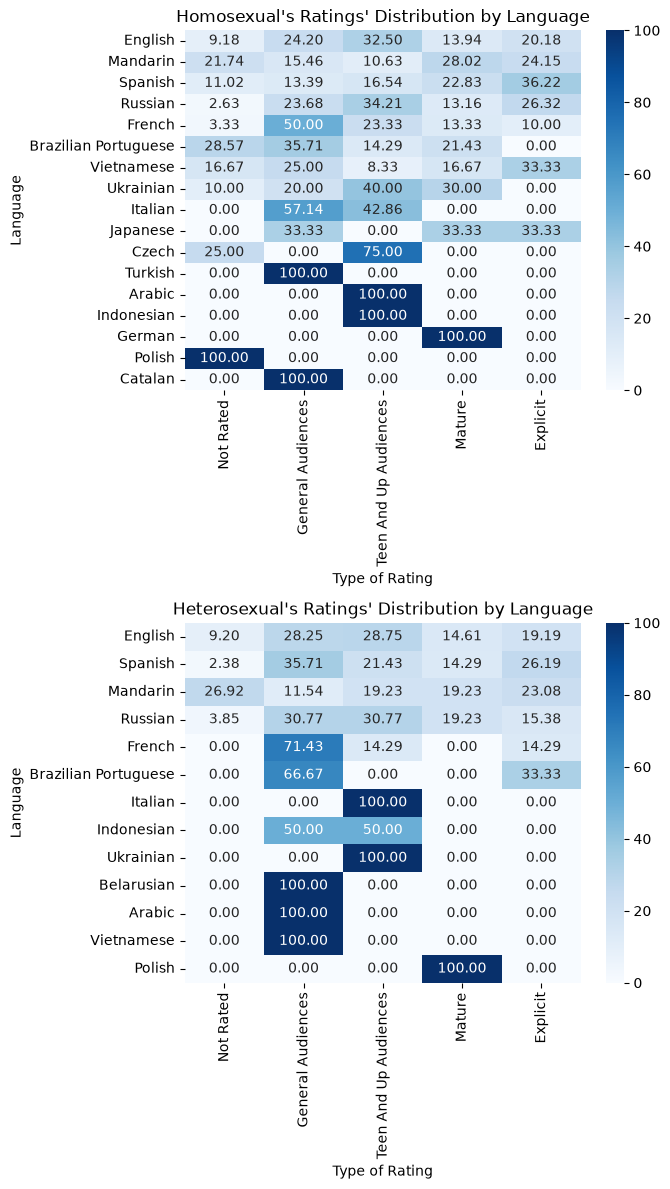

In [94]:
# Filtered by F/F + M/M
# Get numeric values
num_values_ff_mm = df_ff_mm_languages_percentages_ratings.select(["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"]).to_numpy()

# Create heatmap
fig, ax = plt.subplots(2, 1, figsize=(7, 12))

sns.heatmap(
    num_values_ff_mm,
    ax=ax[0],
    annot=True,
    fmt=".2f",
    xticklabels=["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"],
    yticklabels=ff_mm_language_list,
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax[0].set_title("Homosexual's Ratings' Distribution by Language") # Add the title
ax[0].set_xlabel("Type of Rating") # Add the x-axis label
ax[0].set_ylabel("Language") # Add the y-axis label

# Filtered by F/M
# Get numeric values
num_values_fm = df_fm_languages_percentages_ratings.select(["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"]).to_numpy()

sns.heatmap(
    num_values_fm,
    ax=ax[1],
    annot=True,
    fmt=".2f",
    xticklabels=["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"],
    yticklabels=fm_language_list,
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax[1].set_title("Heterosexual's Ratings' Distribution by Language") # Add the title
ax[1].set_xlabel("Type of Rating") # Add the x-axis label
ax[1].set_ylabel("Language") # Add the y-axis label

plt.tight_layout()
plt.show()

## 2. Archive Warnings

### 2.1 Creating the Archive Warnings Datasets

In [8]:
# Filtered by F/F + M/M based on language
df_ff_mm_languages_archive_warnings = pl.DataFrame()
for ff_mm_language in ff_mm_language_list:
    ff_mm_language_archive_warnings = df_metadata.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Language") == ff_mm_language)
    ).select(pl.col("Archive Warning").value_counts()).unnest("Archive Warning").sort("Archive Warning").unpivot(index="Archive Warning", variable_name="count").pivot("Archive Warning", index="count").drop("count").with_columns(pl.lit(ff_mm_language).alias("Language")) # Filter based on language
    df_ff_mm_languages_archive_warnings = pl.concat([df_ff_mm_languages_archive_warnings, ff_mm_language_archive_warnings], how="diagonal") # Concatenate the DataFrames

df_ff_mm_languages_archive_warnings = df_ff_mm_languages_archive_warnings.select(['Language', 'Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']) # Reorder the columns
df_ff_mm_languages_archive_warnings = df_ff_mm_languages_archive_warnings.with_columns(pl.all().fill_null(strategy="zero"))

# Filtered by F/F + M/M based on language
df_fm_languages_archive_warnings = pl.DataFrame()
for fm_language in fm_language_list:
    fm_language_archive_warnings = df_metadata.filter(
        (pl.col("Category") == "F/M") & 
        (pl.col("Language") == fm_language)
    ).select(pl.col("Archive Warning").value_counts()).unnest("Archive Warning").sort("Archive Warning").unpivot(index="Archive Warning", variable_name="count").pivot("Archive Warning", index="count").drop("count").with_columns(pl.lit(fm_language).alias("Language")) # Filter based on language
    df_fm_languages_archive_warnings = pl.concat([df_fm_languages_archive_warnings, fm_language_archive_warnings], how="diagonal") # Concatenate the DataFrames

df_fm_languages_archive_warnings = df_fm_languages_archive_warnings.select(['Language', 'Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']) # Reorder the columns
df_fm_languages_archive_warnings = df_fm_languages_archive_warnings.with_columns(pl.all().fill_null(strategy="zero"))

print("Homosexual Language Archive Warnings Amount:")
df_ff_mm_languages_archive_warnings.show(17)
print("Heterosexual Language Archive Warnings Amount:")
df_fm_languages_archive_warnings.show(17)

# Calculate the Archive Warnings percentage distribution per language
df_ff_mm_languages_percentages_aw = df_ff_mm_languages_archive_warnings.with_columns((pl.exclude("Language") / pl.sum_horizontal(pl.exclude("Language")) * 100)).with_columns(pl.exclude("Language")) # Filtered based on F/F + M/M
# Calculate the Archive Warnings percentage distribution per language
df_fm_languages_percentages_aw = df_fm_languages_archive_warnings.with_columns((pl.exclude("Language") / pl.sum_horizontal(pl.exclude("Language")) * 100)).with_columns(pl.exclude("Language")) # Filtered based on F/M

print("Homosexual Language Archive Warnings Percentage Distribution:")
df_ff_mm_languages_percentages_aw.show(17)
print("Heterosexual Language Archive Warnings Percentage Distribution:")
df_fm_languages_percentages_aw.show(13)

Homosexual Language Archive Warnings Amount:


Language,Creator Chose Not To Use Archive Warnings,No Archive Warnings Apply,Underage Sex,Major Character Death,Graphic Depictions Of Violence,Rape/Non-Con
str,u32,u32,u32,u32,u32,u32
"""English""",1511,2947,210,78,153,37
"""Mandarin""",124,20,27,6,10,3
"""Spanish""",46,20,23,2,4,5
"""Russian""",9,26,0,1,0,1
"""French""",6,18,0,1,1,0
"""Brazilian Portuguese""",9,4,1,0,0,0
"""Vietnamese""",5,1,3,0,0,2
"""Ukrainian""",6,3,1,0,0,0
"""Italian""",4,3,0,0,0,0


Heterosexual Language Archive Warnings Amount:


Language,Creator Chose Not To Use Archive Warnings,No Archive Warnings Apply,Underage Sex,Major Character Death,Graphic Depictions Of Violence,Rape/Non-Con
str,u32,u32,u32,u32,u32,u32
"""English""",1156,2302,120,97,145,47
"""Spanish""",16,15,1,1,5,2
"""Mandarin""",11,5,3,2,0,2
"""Russian""",7,15,0,1,0,1
"""French""",1,4,0,0,0,0
"""Brazilian Portuguese""",2,0,0,0,0,0
"""Italian""",0,1,0,0,0,0
"""Indonesian""",2,0,0,0,0,0
"""Ukrainian""",1,1,0,0,0,0


Homosexual Language Archive Warnings Percentage Distribution:


Language,Creator Chose Not To Use Archive Warnings,No Archive Warnings Apply,Underage Sex,Major Character Death,Graphic Depictions Of Violence,Rape/Non-Con
str,f64,f64,f64,f64,f64,f64
"""English""",30.611831,59.704214,4.254457,1.580227,3.099676,0.749595
"""Mandarin""",65.263158,10.526316,14.210526,3.157895,5.263158,1.578947
"""Spanish""",46.0,20.0,23.0,2.0,4.0,5.0
"""Russian""",24.324324,70.27027,0.0,2.702703,0.0,2.702703
"""French""",23.076923,69.230769,0.0,3.846154,3.846154,0.0
"""Brazilian Portuguese""",64.285714,28.571429,7.142857,0.0,0.0,0.0
"""Vietnamese""",45.454545,9.090909,27.272727,0.0,0.0,18.181818
"""Ukrainian""",60.0,30.0,10.0,0.0,0.0,0.0
"""Italian""",57.142857,42.857143,0.0,0.0,0.0,0.0


Heterosexual Language Archive Warnings Percentage Distribution:


Language,Creator Chose Not To Use Archive Warnings,No Archive Warnings Apply,Underage Sex,Major Character Death,Graphic Depictions Of Violence,Rape/Non-Con
str,f64,f64,f64,f64,f64,f64
"""English""",29.893975,59.529351,3.103181,2.508404,3.749677,1.215412
"""Spanish""",40.0,37.5,2.5,2.5,12.5,5.0
"""Mandarin""",47.826087,21.73913,13.043478,8.695652,0.0,8.695652
"""Russian""",29.166667,62.5,0.0,4.166667,0.0,4.166667
"""French""",20.0,80.0,0.0,0.0,0.0,0.0
"""Brazilian Portuguese""",100.0,0.0,0.0,0.0,0.0,0.0
"""Italian""",0.0,100.0,0.0,0.0,0.0,0.0
"""Indonesian""",100.0,0.0,0.0,0.0,0.0,0.0
"""Ukrainian""",50.0,50.0,0.0,0.0,0.0,0.0


### 2.2 Visualizing the Archive Warnings Datasets

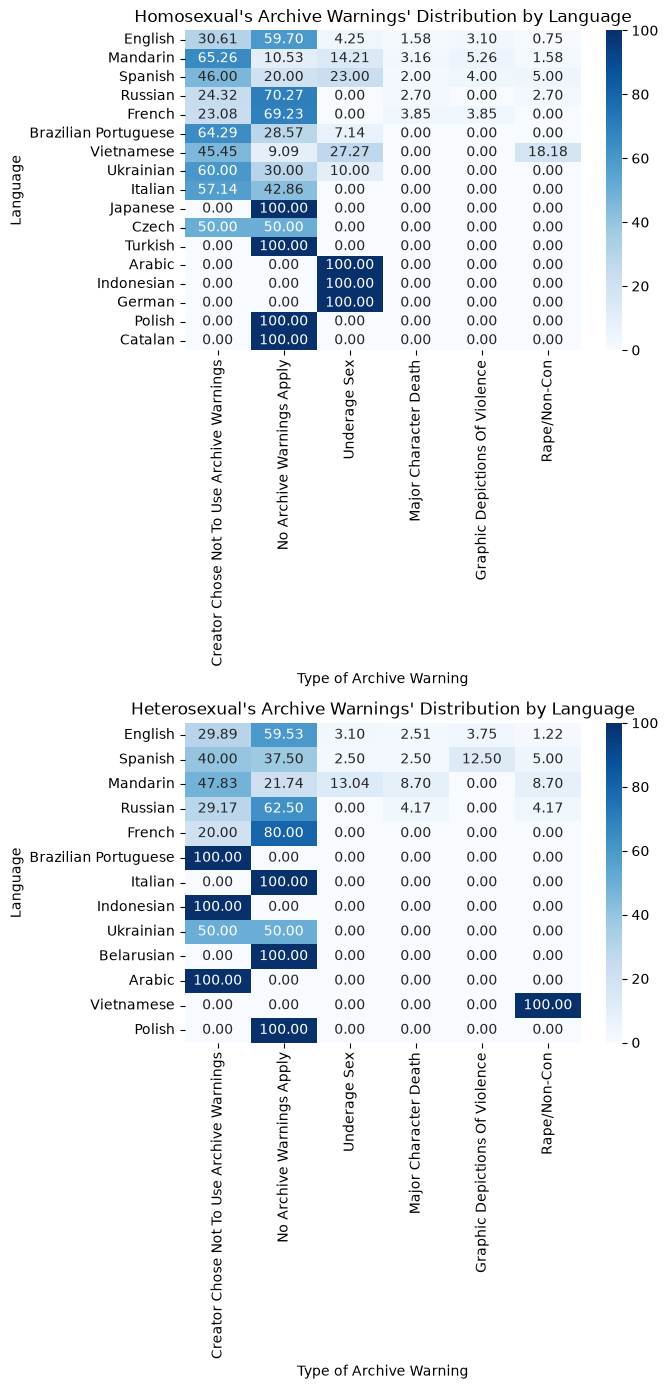

In [97]:
# Filtered by F/F + M/M
# Get numeric values
num_values_ff_mm = df_ff_mm_languages_percentages_aw.select(['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']).to_numpy()

# Create heatmap
fig, ax = plt.subplots(2, 1, figsize=(7, 14))

sns.heatmap(
    num_values_ff_mm,
    ax=ax[0],
    annot=True,
    fmt=".2f",
    xticklabels=['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con'],
    yticklabels=ff_mm_language_list,
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax[0].set_title("Homosexual's Archive Warnings' Distribution by Language") # Add the title
ax[0].set_xlabel("Type of Archive Warning") # Add the x-axis label
ax[0].set_ylabel("Language") # Add the y-axis label

# Filtered by F/M
# Get numeric values
num_values_fm = df_fm_languages_percentages_aw.select(['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']).to_numpy()

sns.heatmap(
    num_values_fm,
    ax=ax[1],
    annot=True,
    fmt=".2f",
    xticklabels=['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con'],
    yticklabels=fm_language_list,
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax[1].set_title("Heterosexual's Archive Warnings' Distribution by Language") # Add the title
ax[1].set_xlabel("Type of Archive Warning") # Add the x-axis label
ax[1].set_ylabel("Language") # Add the y-axis label

plt.tight_layout()
plt.show()

## 3. Additional Tags

### 3.1 Creating the Additional Tags Datasets

In [11]:
fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]
categories = ["F/F", "M/M", "F/M"]

In [ ]:
def create_temp_df(fandom, category, language):
    """
    Creates a DataFrame of the additional tags frequencies.

    Parameters:
        fandom (string): Target fandom.
        category (string): Target relationship category.
        language (string): Language of the fan work.
    returns:
        df_temp (DataFrame): Consisting of Fandom, Category, Additional Tags, and Freq columns.
    """
    # Filter the df_cats_and_fandoms DataFrame based on the target fandom and category
    df_filtered = df_metadata.filter(
        (pl.col("Fandom") == fandom) &
        (pl.col("Category") == category) &
        (pl.col("Language") == language)
        
    ).with_row_index()

    # Convert the Additional Tags column from a string to a list of strings
    df_filtered = df_filtered.with_columns(
        pl.col("Additional Tags").str.split(", "),
    )
    
    tags_freq = {}
    for row in df_filtered.iter_rows(named=True):
        try:
            for tag in row["Additional Tags"]:
                # Check if the Additional Tags key exists
                if tag not in tags_freq:
                    # Create the Additional Tags key
                    tags_freq[tag] = 0
                # Increase the Additional Tags frequency count with 1
                tags_freq[tag] += 1
        except:
            pass

    # Sort the tags_freq dictionary based on descending additional tag frequency order
    tags_freq = dict(sorted(tags_freq.items(), key=lambda item: item[1], reverse=True))

    # Create a DataFrame
    df_temp = pl.DataFrame({
        "Fandom": fandom,
        "Category": category,
        "Language": language,
        "Additional Tags": tags_freq.keys(),
        "Freq": tags_freq.values()
    })

    return df_temp

In [12]:
# Combine the language lists
languages = ff_mm_language_list + list(set(fm_language_list) - set(ff_mm_language_list))
languages

['English',
 'Mandarin',
 'Spanish',
 'Russian',
 'French',
 'Brazilian Portuguese',
 'Vietnamese',
 'Ukrainian',
 'Italian',
 'Japanese',
 'Czech',
 'Turkish',
 'Arabic',
 'Indonesian',
 'German',
 'Polish',
 'Catalan',
 'Belarusian']

In [19]:
# Calculate the additional tags frequency based on language
df_main = pl.DataFrame()
for fandom in fandoms:
    for category in categories:
        for language in languages:
            # Concatenate the temporary DataFrame to df_main
            df_main = pl.concat([df_main, create_temp_df(fandom, category, language)])

df_main

Fandom,Category,Language,Additional Tags,Freq
str,str,str,str,i64
"""DC's Legends of Tomorrow (TV)""","""F/F""","""English""","""Fluff""",282
"""DC's Legends of Tomorrow (TV)""","""F/F""","""English""","""Angst""",149
"""DC's Legends of Tomorrow (TV)""","""F/F""","""English""","""AvaLance""",132
"""DC's Legends of Tomorrow (TV)""","""F/F""","""English""","""Hurt/Comfort""",107
"""DC's Legends of Tomorrow (TV)""","""F/F""","""English""","""Angst with a Happy Ending""",68
…,…,…,…,…
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""Italian""","""Mention of Racism""",1
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""Italian""","""mention of body shaming""",1
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""Italian""","""Slurs""",1


In [90]:
df_add_tag_annotation = pl.read_csv("./data/df_additional_tag_annotations.csv") # Read the CSV file

# Concatenate the DataFrames
df_annotated_additional_tags = pl.concat([df_main, df_add_tag_annotation], how="align")
df_annotated_additional_tags

Fandom,Category,Language,Additional Tags,Freq,Character,Narrative,Porn,Kink
str,str,str,str,i64,str,str,str,str
"""Avatar: The Last Airbender (Ca…","""F/M""","""English""","""!!TW!!""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""English""","""""Has she always been good at t…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""English""","""""I love the smell of incest 😍😍…",1,"""No Character""","""No Narrative""","""Is Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""English""","""""I loved her to the point of i…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""DC's Legends of Tomorrow (TV)""","""F/F""","""English""","""""Mayday Mayday!""""",1,"""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
…,…,…,…,…,…,…,…,…
"""Spider-Man: Spider-Verse (Sony…","""M/M""","""Mandarin""","""高中生养蜘蛛""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""M/M""","""Mandarin""","""鱼哭了海知道狗哭了谁知道""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""English""","""🍆💦""",3,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""


In [39]:
def label_freq(df):
    """
    Calculates the frequency of the annotations.

    Parameter:
        df (DataFrame): Filtered DataFrame.
    Returns:
        df_label_freq (DataFrame): Contains the frequency of the annotations.
    """
    # Add the frequency of the annotations based on unique additional tags
    categories = ["Character", "Narrative", "Porn", "Kink"]

    df_unique_values = pl.DataFrame()
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[0]).value_counts()).unnest(categories[0]).rename({"Character": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[1]).value_counts()).unnest(categories[1]).rename({"Narrative": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[2]).value_counts()).unnest(categories[2]).rename({"Porn": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[3]).value_counts()).unnest(categories[3]).rename({"Kink": "Label"})])
    df_unique_values = df_unique_values.rename({"count": "Unique Additional Tags Frequency"})

    # Turn into lists
    char_list = ['No Character', 'Biography', 'Physical Feature', 'Emotion/Mental State', 'Relationship', "Personality"]
    nar_list = ['No Narrative', 'Plot', 'Event-related/Action', 'Theme/Genre', 'WorldSetting', 'Narrative Methods', 'Format']
    porn_list = ['Not Porn', 'Is Porn']
    kink_list = ['Not Kink', 'Is Kink']

    # Append the frequency of the annotations based on total additional tags
    df_freq_count = pl.DataFrame()
    for char_label in char_list:
        df_temp_char = pl.DataFrame({
            "Label": char_label,
            "Freq": df.filter(pl.col("Character") == char_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_char])
    for nar_label in nar_list:
        df_temp_nar = pl.DataFrame({
            "Label": nar_label,
            "Freq": df.filter(pl.col("Narrative") == nar_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_nar])
    for porn_label in porn_list:
        df_temp_porn = pl.DataFrame({
            "Label": porn_label,
            "Freq": df.filter(pl.col("Porn") == porn_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_porn])
    for kink_label in kink_list:
        df_temp_kink = pl.DataFrame({
            "Label": kink_label,
            "Freq": df.filter(pl.col("Kink") == kink_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_kink])
    
    df_freq_count = df_freq_count.rename({"Freq": "Total Additional Tags Frequency"})

    labels = df_freq_count.to_series(0)
    df_label_freq = pl.concat([df_unique_values, df_freq_count], how='align')
    df_label_freq = df_label_freq.sort(pl.col("Total Additional Tags Frequency"), descending=True)
    
    return df_label_freq

In [62]:
character_labels = ["No Character", "Biography", "Physical Feature", "Emotion/Mental State", "Relationship", "Personality"]
narrative_labels = ["No Narrative", "Plot", "Event-related/Action", "Theme/Genre", "WorldSetting", "Narrative Methods", "Format"]
porn_labels = ["Not Porn", "Is Porn"]
kink_labels = ["Not Kink", "Is Kink"]

In [87]:
# Filtered by F/F + M/M per language
df_add_tags_ff_mm_languages = pl.DataFrame()
for language in ff_mm_language_list:
    df_add_tags_ff_mm = df_annotated_additional_tags.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Language") == language)
    ).group_by("Additional Tags").agg(pl.col("Freq").sum()) # Calculate the frequency of the additional tags
    df_add_tags_ff_mm = df_add_tags_ff_mm.join(df_add_tag_annotation, on="Additional Tags") # Add the annotations
    df_add_tags_ff_mm = label_freq(df_add_tags_ff_mm) # Calculate the frequency of the annotation labels
    df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
    df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category
    df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns(pl.all().fill_null(strategy="zero")) # Change Null to 0
    df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns(new_column=pl.lit(language)).rename({"new_column": "Language"}) # Add the Language column
    df_add_tags_ff_mm = df_add_tags_ff_mm.fill_nan(0)
    df_add_tags_ff_mm_languages = pl.concat([df_add_tags_ff_mm_languages, df_add_tags_ff_mm], how="vertical") # Concatenate the DataFrame

# Filtered by F/M per language
df_add_tags_fm_languages = pl.DataFrame()
for language in fm_language_list:
    df_add_tags_fm = df_annotated_additional_tags.filter(
        (pl.col("Category") == "F/M") &
        (pl.col("Language") == language)
    ).group_by("Additional Tags").agg(pl.col("Freq").sum()) # Calculate the frequency of the additional tags

    df_add_tags_fm = df_add_tags_fm.join(df_add_tag_annotation, on="Additional Tags") # Add the annotations
    df_add_tags_fm = label_freq(df_add_tags_fm) # Calculate the frequency of the annotation labels
    df_add_tags_fm = df_add_tags_fm.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
    df_add_tags_fm = df_add_tags_fm.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category
    df_add_tags_fm = df_add_tags_fm.with_columns(pl.all().fill_null(strategy="zero")) # Change Null to 0
    df_add_tags_fm = df_add_tags_fm.with_columns(new_column=pl.lit(language)).rename({"new_column": "Language"}) # Add the Language column
    df_add_tags_fm = df_add_tags_fm.fill_nan(0)
    df_add_tags_fm_languages = pl.concat([df_add_tags_fm_languages, df_add_tags_fm], how="vertical") # Concatenate the DataFrame

print("Homosexual Additional Tag Annotations' per Language Amount:")
df_add_tags_ff_mm_languages.show()
print("Heterosexual Additional Tag Annotations' per Language Amount:")
df_add_tags_fm_languages.show()

df_add_tags_ff_mm_languages = df_add_tags_ff_mm_languages.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)
df_add_tags_fm_languages = df_add_tags_fm_languages.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)

print("Homosexual Additional Tag Annotations' per Language Amount:")
df_add_tags_ff_mm_languages.show()
print("Heterosexual Additional Tag Annotations' per Language Amount:")
df_add_tags_fm_languages.show()

# Pivot the tables
df_add_tags_ff_mm_languages = df_add_tags_ff_mm_languages.pivot("Language", index="Label", values="Total Additional Tags in %")
df_add_tags_fm_languages = df_add_tags_fm_languages.pivot("Language", index="Label", values="Total Additional Tags in %")

print("Homosexual Additional Tag Annotations' per Language Amount:")
df_add_tags_ff_mm_languages.show(17)
print("Heterosexual Additional Tag Annotations' per Language Amount:")
df_add_tags_fm_languages.show(17)

# Turn column into list
ff_mm_labels = df_add_tags_ff_mm_languages["Label"].to_list()
fm_labels = df_add_tags_fm_languages["Label"].to_list()

# Turn languages into numerical values
ff_mm_values = df_add_tags_ff_mm_languages.select(df_add_tags_ff_mm_languages.columns[1:]).to_numpy()
fm_values = df_add_tags_fm_languages.select(df_add_tags_fm_languages.columns[1:]).to_numpy()

Homosexual Additional Tag Annotations' per Language Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %,Language
str,u32,i64,str,f64,f64,str
"""Not Kink""",15753,42421,"""Kink""",97.584092,95.283125,"""English"""
"""Not Porn""",14924,38871,"""Porn""",92.448739,87.30936,"""English"""
"""No Character""",9844,23255,"""Character""",60.979991,52.233777,"""English"""
"""No Narrative""",9268,18737,"""Narrative""",57.411881,42.085757,"""English"""
"""Event-related/Action""",2849,10540,"""Narrative""",17.648516,23.674221,"""English"""


Heterosexual Additional Tag Annotations' per Language Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %,Language
str,u32,i64,str,f64,f64,str
"""Not Kink""",11685,32951,"""Kink""",97.57014,95.063759,"""English"""
"""Not Porn""",11005,29494,"""Porn""",91.892118,85.090301,"""English"""
"""No Character""",7338,18549,"""Character""",61.272545,53.513935,"""English"""
"""No Narrative""",6631,13777,"""Narrative""",55.369071,39.746697,"""English"""
"""Event-related/Action""",2171,8213,"""Narrative""",18.127923,23.694536,"""English"""


Homosexual Additional Tag Annotations' per Language Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %,Language
str,u32,i64,str,f64,f64,str
"""No Character""",9844,23255,"""Character""",60.979991,52.233777,"""English"""
"""No Narrative""",9268,18737,"""Narrative""",57.411881,42.085757,"""English"""
"""Event-related/Action""",2849,10540,"""Narrative""",17.648516,23.674221,"""English"""
"""Relationship""",2072,7673,"""Character""",12.835285,17.234563,"""English"""
"""Biography""",2295,6518,"""Character""",14.216688,14.640282,"""English"""


... (2 outputs left out)

Homosexual Additional Tag Annotations' per Language Amount:


Label,English,Mandarin,Spanish,Russian,French,Brazilian Portuguese,Vietnamese,Ukrainian,Italian,Japanese,Czech,Turkish,Arabic,Indonesian,German,Polish,Catalan
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""No Character""",52.233777,60.965517,42.307692,52.682927,50.393701,29.230769,55.445545,60.869565,53.333333,15.789474,26.315789,100.0,73.333333,33.333333,60.0,0.0,33.333333
"""No Narrative""",42.085757,53.655172,36.10675,32.682927,38.582677,60.0,41.584158,59.42029,37.777778,78.947368,63.157895,50.0,53.333333,40.0,0.0,0.0,50.0
"""Event-related/Action""",23.674221,23.172414,29.356358,22.439024,18.897638,12.307692,35.643564,13.043478,8.888889,10.526316,19.298246,0.0,26.666667,13.333333,80.0,0.0,0.0
"""Relationship""",17.234563,13.931034,15.149137,18.04878,20.472441,15.384615,15.841584,14.492754,26.666667,10.526316,15.789474,0.0,13.333333,53.333333,20.0,0.0,33.333333
"""Biography""",14.640282,16.0,23.704867,17.073171,14.173228,32.307692,17.821782,13.043478,15.555556,68.421053,26.315789,0.0,6.666667,13.333333,0.0,0.0,0.0
"""Is Porn""",12.69064,22.068966,23.155416,19.02439,6.299213,10.769231,40.594059,7.246377,4.444444,21.052632,5.263158,0.0,26.666667,13.333333,40.0,0.0,0.0
"""Theme/Genre""",12.533411,9.793103,8.712716,20.487805,13.385827,4.615385,4.950495,5.797101,20.0,0.0,1.754386,0.0,13.333333,13.333333,20.0,0.0,0.0
"""Emotion/Mental State""",11.745019,6.344828,10.596546,10.731707,13.385827,12.307692,4.950495,8.695652,4.444444,0.0,29.824561,0.0,6.666667,0.0,20.0,0.0,16.666667
"""Plot""",9.63141,4.827586,11.22449,8.292683,7.874016,10.769231,8.910891,11.594203,13.333333,0.0,5.263158,25.0,6.666667,26.666667,0.0,0.0,16.666667


Heterosexual Additional Tag Annotations' per Language Amount:


Label,English,Spanish,Mandarin,Russian,French,Brazilian Portuguese,Italian,Indonesian,Ukrainian,Belarusian,Arabic,Vietnamese,Polish
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""No Character""",53.513935,55.666667,55.789474,48.502994,60.714286,31.578947,63.157895,62.5,72.727273,50.0,100.0,50.0,20.0
"""No Narrative""",39.746697,35.166667,63.157895,45.508982,21.428571,42.105263,36.842105,43.75,27.272727,50.0,0.0,16.666667,60.0
"""Event-related/Action""",23.694536,31.0,11.578947,11.377246,10.714286,21.052632,42.105263,6.25,27.272727,0.0,0.0,66.666667,0.0
"""Relationship""",17.203277,15.333333,23.157895,15.568862,14.285714,36.842105,21.052632,0.0,0.0,0.0,0.0,16.666667,0.0
"""Is Porn""",14.909699,21.166667,20.0,11.377246,10.714286,21.052632,21.052632,6.25,0.0,0.0,0.0,83.333333,0.0
"""Biography""",13.983613,12.333333,13.684211,16.766467,7.142857,15.789474,10.526316,25.0,9.090909,37.5,0.0,0.0,80.0
"""Theme/Genre""",13.822053,14.0,11.578947,20.958084,25.0,26.315789,5.263158,6.25,9.090909,0.0,0.0,0.0,0.0
"""Emotion/Mental State""",10.896659,10.5,6.315789,18.562874,17.857143,10.526316,5.263158,12.5,18.181818,0.0,0.0,16.666667,0.0
"""Plot""",10.013848,7.0,4.210526,8.383234,14.285714,5.263158,0.0,0.0,18.181818,37.5,0.0,16.666667,20.0


### 3.2 Visualizing the Additional Tags Datasets

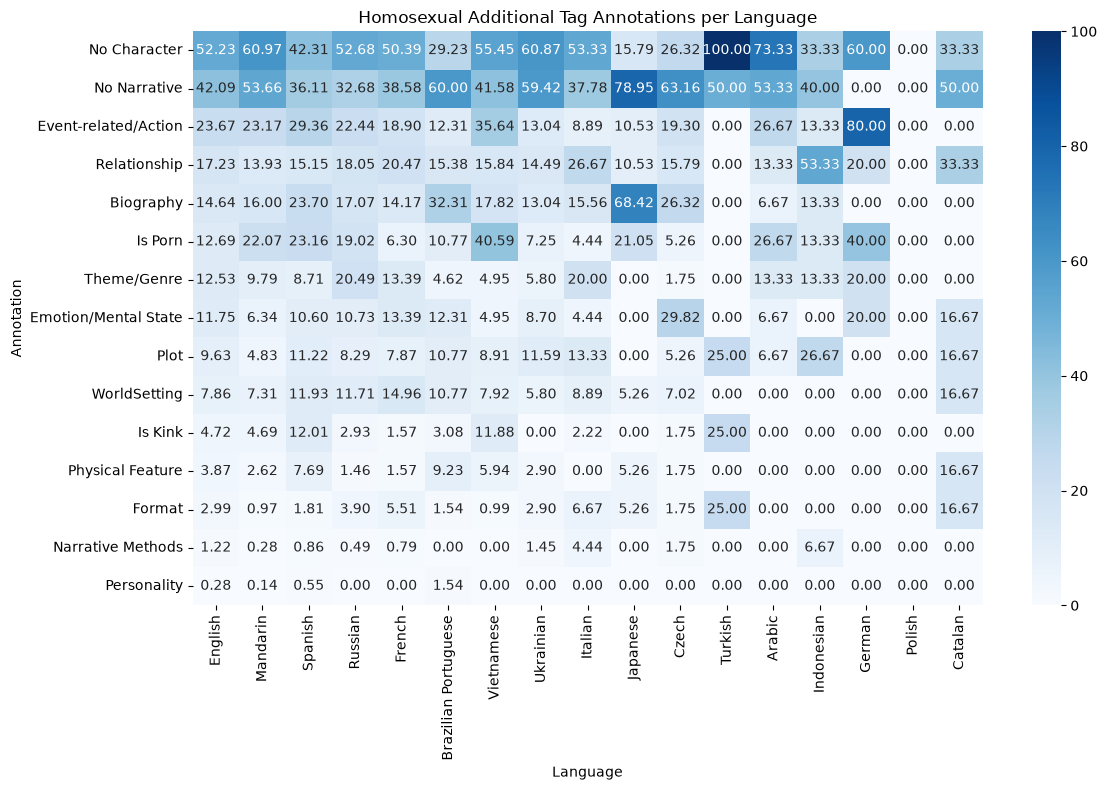

In [118]:
# Plot the heatmaps
fig, ax = plt.subplots(figsize=(12, 8))

vmax = max(ff_mm_values.max(), fm_values.max()) # Set the max value based on the max. %

# Filtered by F/F + M/M
sns.heatmap(
    ff_mm_values,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=vmax,
    xticklabels=df_add_tags_ff_mm_languages.columns[1:],
    yticklabels=ff_mm_labels,
    ax=ax
)

ax.set_title("Homosexual Additional Tag Annotations per Language")
ax.set_xlabel("Language")
ax.set_ylabel("Annotation")

plt.tight_layout()
plt.show()

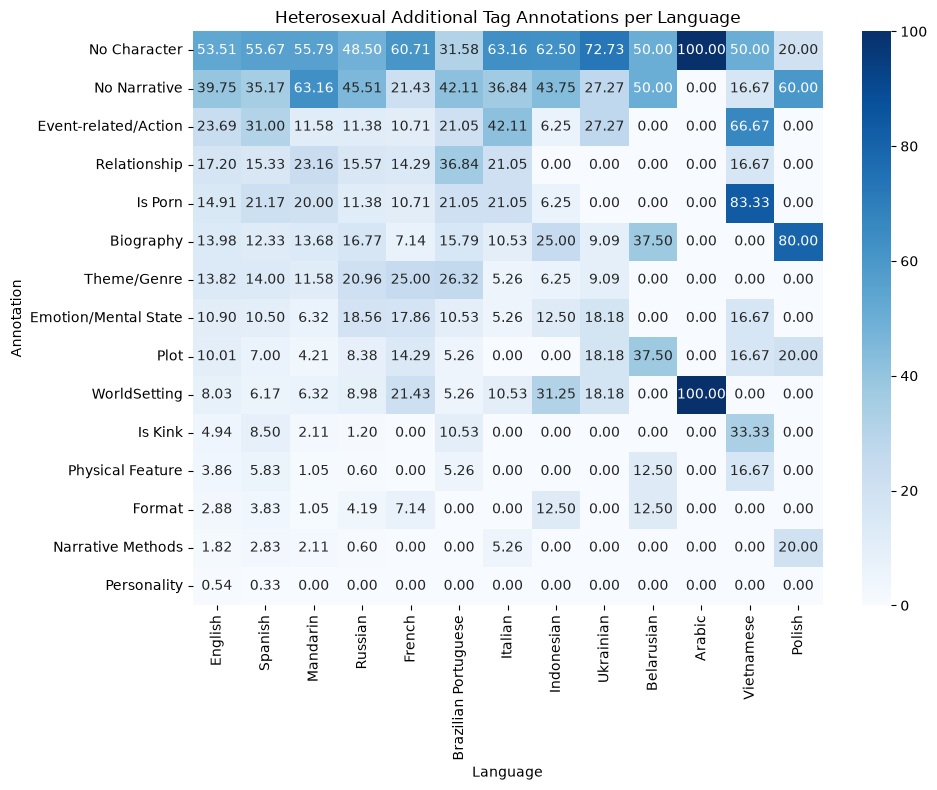

In [117]:
# Plot the heatmaps
fig, ax = plt.subplots(figsize=(10, 8))

vmax = max(ff_mm_values.max(), fm_values.max()) # Set the max value based on the max. %

# Filtered by F/M
sns.heatmap(
    fm_values,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=vmax,
    xticklabels=df_add_tags_fm_languages.columns[1:],
    yticklabels=fm_labels,
    ax=ax
)

ax.set_title("Heterosexual Additional Tag Annotations per Language")
ax.set_xlabel("Language")
ax.set_ylabel("Annotation")

plt.tight_layout()
plt.show()